# **Tutorial:** Custom YOLO Object Detection with RoboFlow

In this tutorial, you'll learn how to create a custom YOLO object detection model using your own classes and annotations with RoboFlow.

**Custom classes (not included in COCO):** `cell phone charger` and `pencil`.

> Run on Google Colab with a GPU: `Runtime > Change runtime type > T4 GPU`.

### **Step 1: Install Required Dependencies**

In [1]:
%pip install -q ultralytics roboflow

### **Step 2: Import Required Libraries**

In [2]:
import cv2
from roboflow import Roboflow
from ultralytics import YOLO
import matplotlib.pyplot as plt
import os
from IPython.display import Image, display
from google.colab import files

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


### **Step 3: Set Up RoboFlow Account**

1. Go to RoboFlow and create a free account
2. Create a new project and select "Object Detection" as project type
3. Choose "YOLOv8" as the model format
4. Classes: `cell phone charger` and `pencil`

### **Step 4: Upload and Annotate Your Images**

#### Using RoboFlow Web Interface:

1. Click "Upload" to add your images
2. Use the annotation tool to draw bounding boxes around objects
3. Assign the correct class labels to each bounding box
4. Apply preprocessing and augmentation as needed

#### Dataset details (fill in):

| Item | Value |
|------|-------|
| Original images | `__` |
| `cell phone charger` annotations | `__` |
| `pencil` annotations | `__` |
| Train / Valid / Test | `70 / 20 / 10 %` |
| Augmentations | `__` |

### **Step 5. Download your Custom your Dataset**

1. In RoboFlow, go to your project dashboard
2. Click "Generate" to create a dataset version
3. Apply any desired augmentations
4. Click "Export" and select "YOLOv**x**" format (**x** the version you are using)
5. Copy the download code

In [20]:

from roboflow import Roboflow
rf = Roboflow(api_key="hyVribl6tBRwAhh9uk9N")
project = rf.workspace("jeffersons-workspace-ydmz5").project("sauce-line-inspection-redpn")
version = project.version(2)
dataset = version.download("yolo26")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Sauce-Line-Inspection-2 in yolo26:: 100%|██████████| 302/302 [00:00<00:00, 9761.64it/s]


### **Step 6: Train Your Custom YOLO Model**

In [32]:
# Load a small YOLO model (great balance between speed and accuracy)
model = YOLO('yolo11s.pt')

# Train the model with optimal epochs and patience
results = model.train(
    data=f'{dataset.location}/data.yaml',  # Path to dataset config
    epochs=50,      # Faster training with 50 epochs
    patience=15,    # Stop early if there's no improvement in 15 epochs
    imgsz=640,      # Image size
    batch=16,       # Batch size
    name='custom_yolo_model',  # Name for the training run
    exist_ok=True
)

BEST_WEIGHTS = os.path.join(str(model.trainer.save_dir), 'weights', 'best.pt')

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Sauce-Line-Inspection-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=custom_yolo_model, nbs=64, nms=None, opset=None,

### **Step 7: Evaluate Your Model**

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,961 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 890.5±144.5 MB/s, size: 39.2 KB)
val: Scanning /content/Sauce-Line-Inspection-2/valid/labels.cache... 12 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 12/12 3.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 3.9it/s 0.3s
                   all         12         14      0.594      0.714      0.634      0.315
     charger and cable          7          7      0.733      0.714       0.82      0.399
                pencil          7          7      0.456      0.714      0.447      0.231
Speed: 0.4ms preprocess, 12.8ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /content/runs/detect/val-5
Precision: 0.594
Recall:    0.714
mAP50:     0.634
mAP50-95:  0.315
charger and cable:

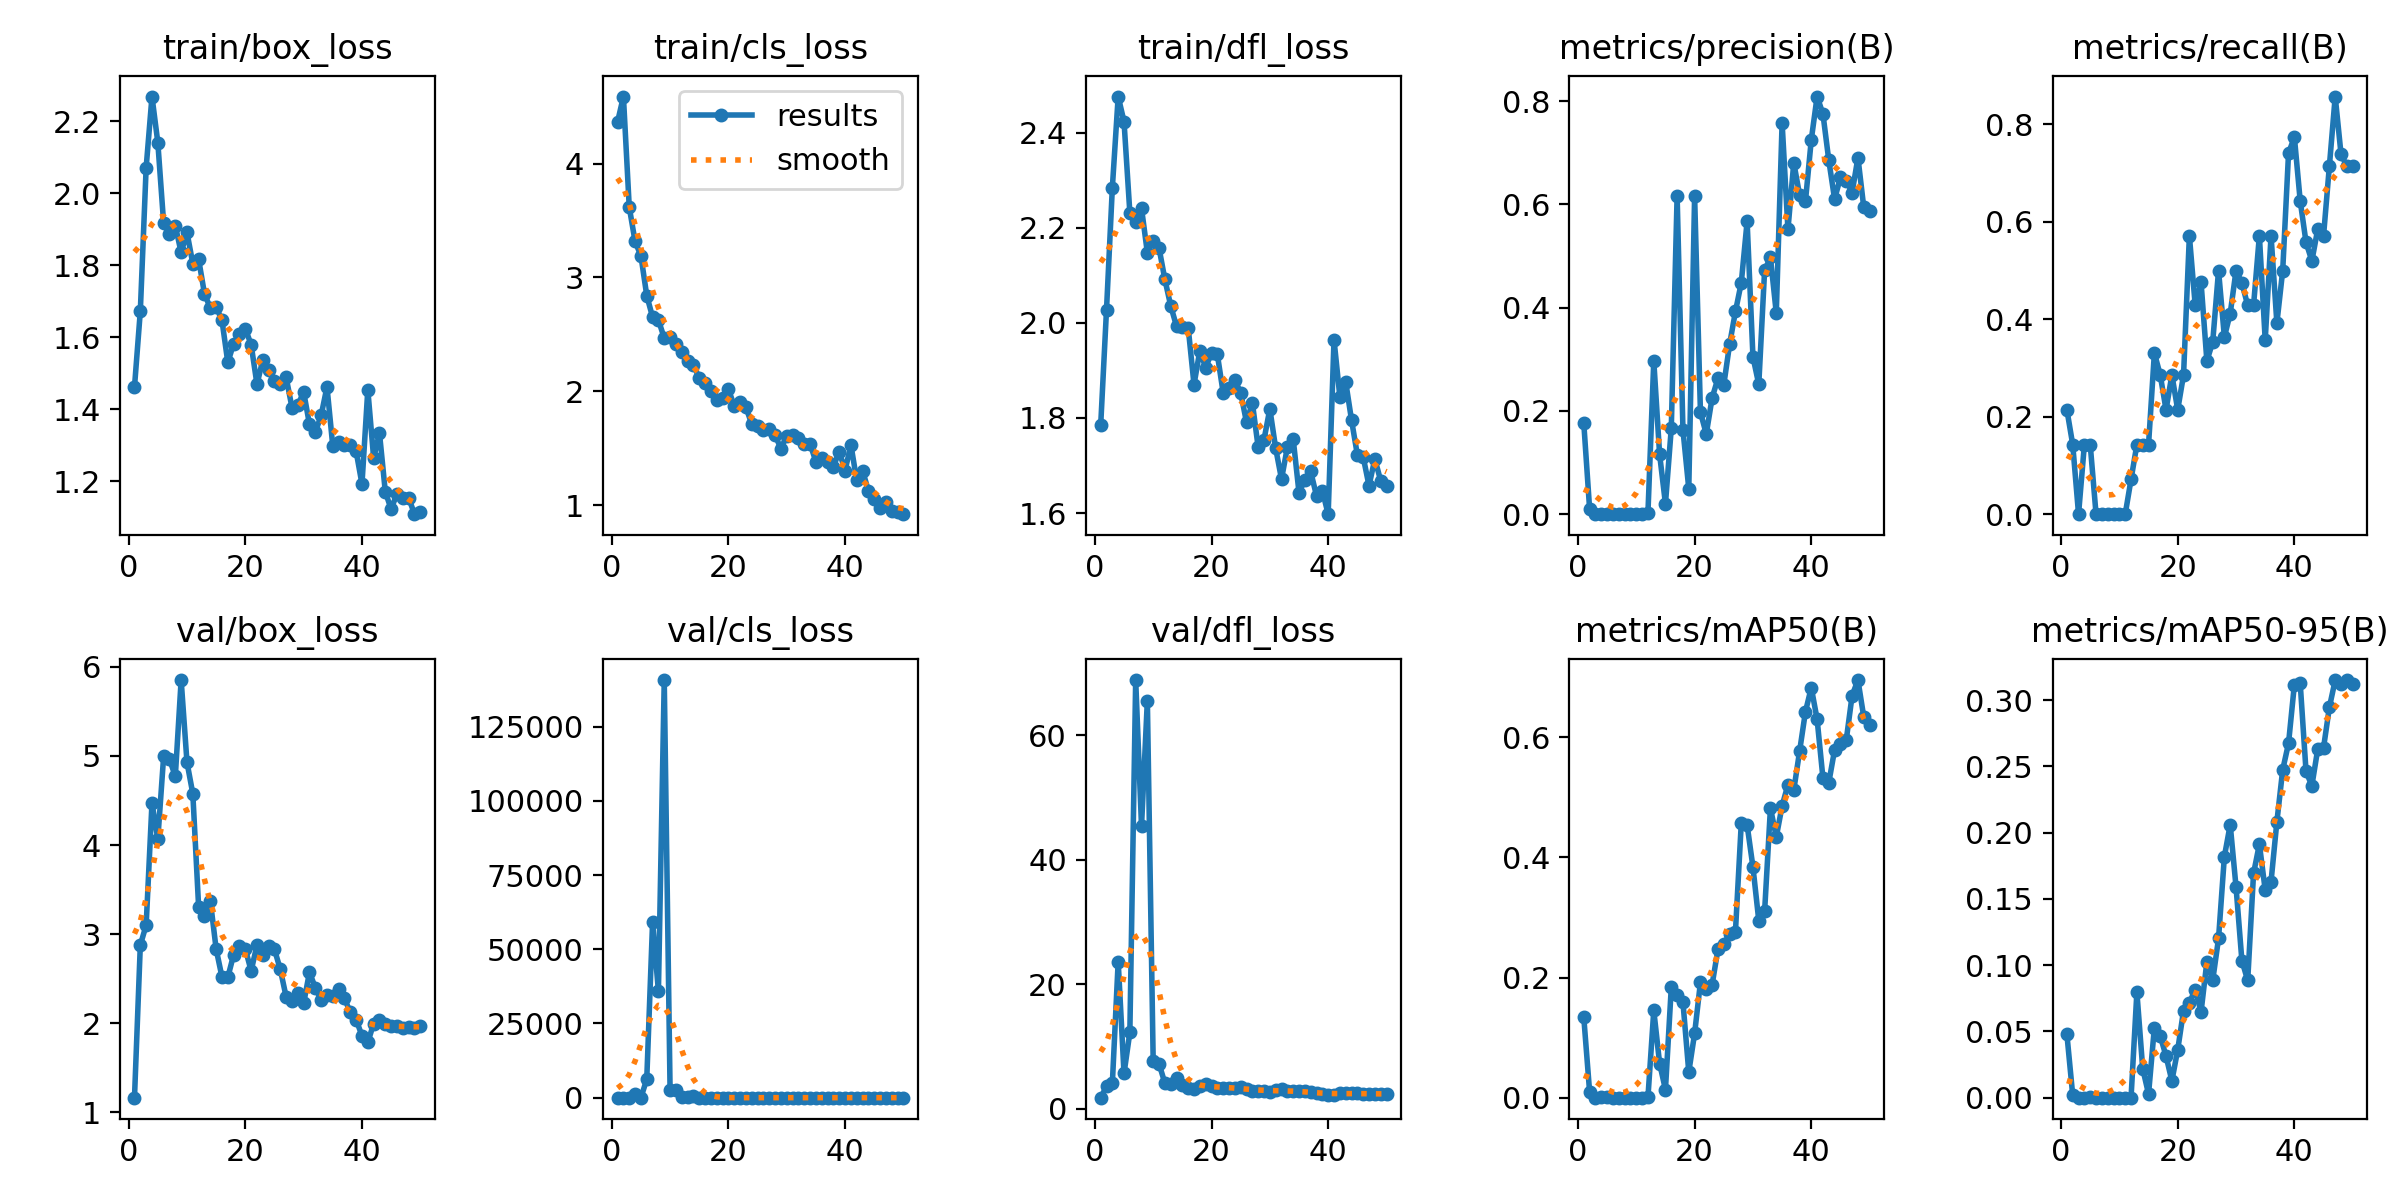

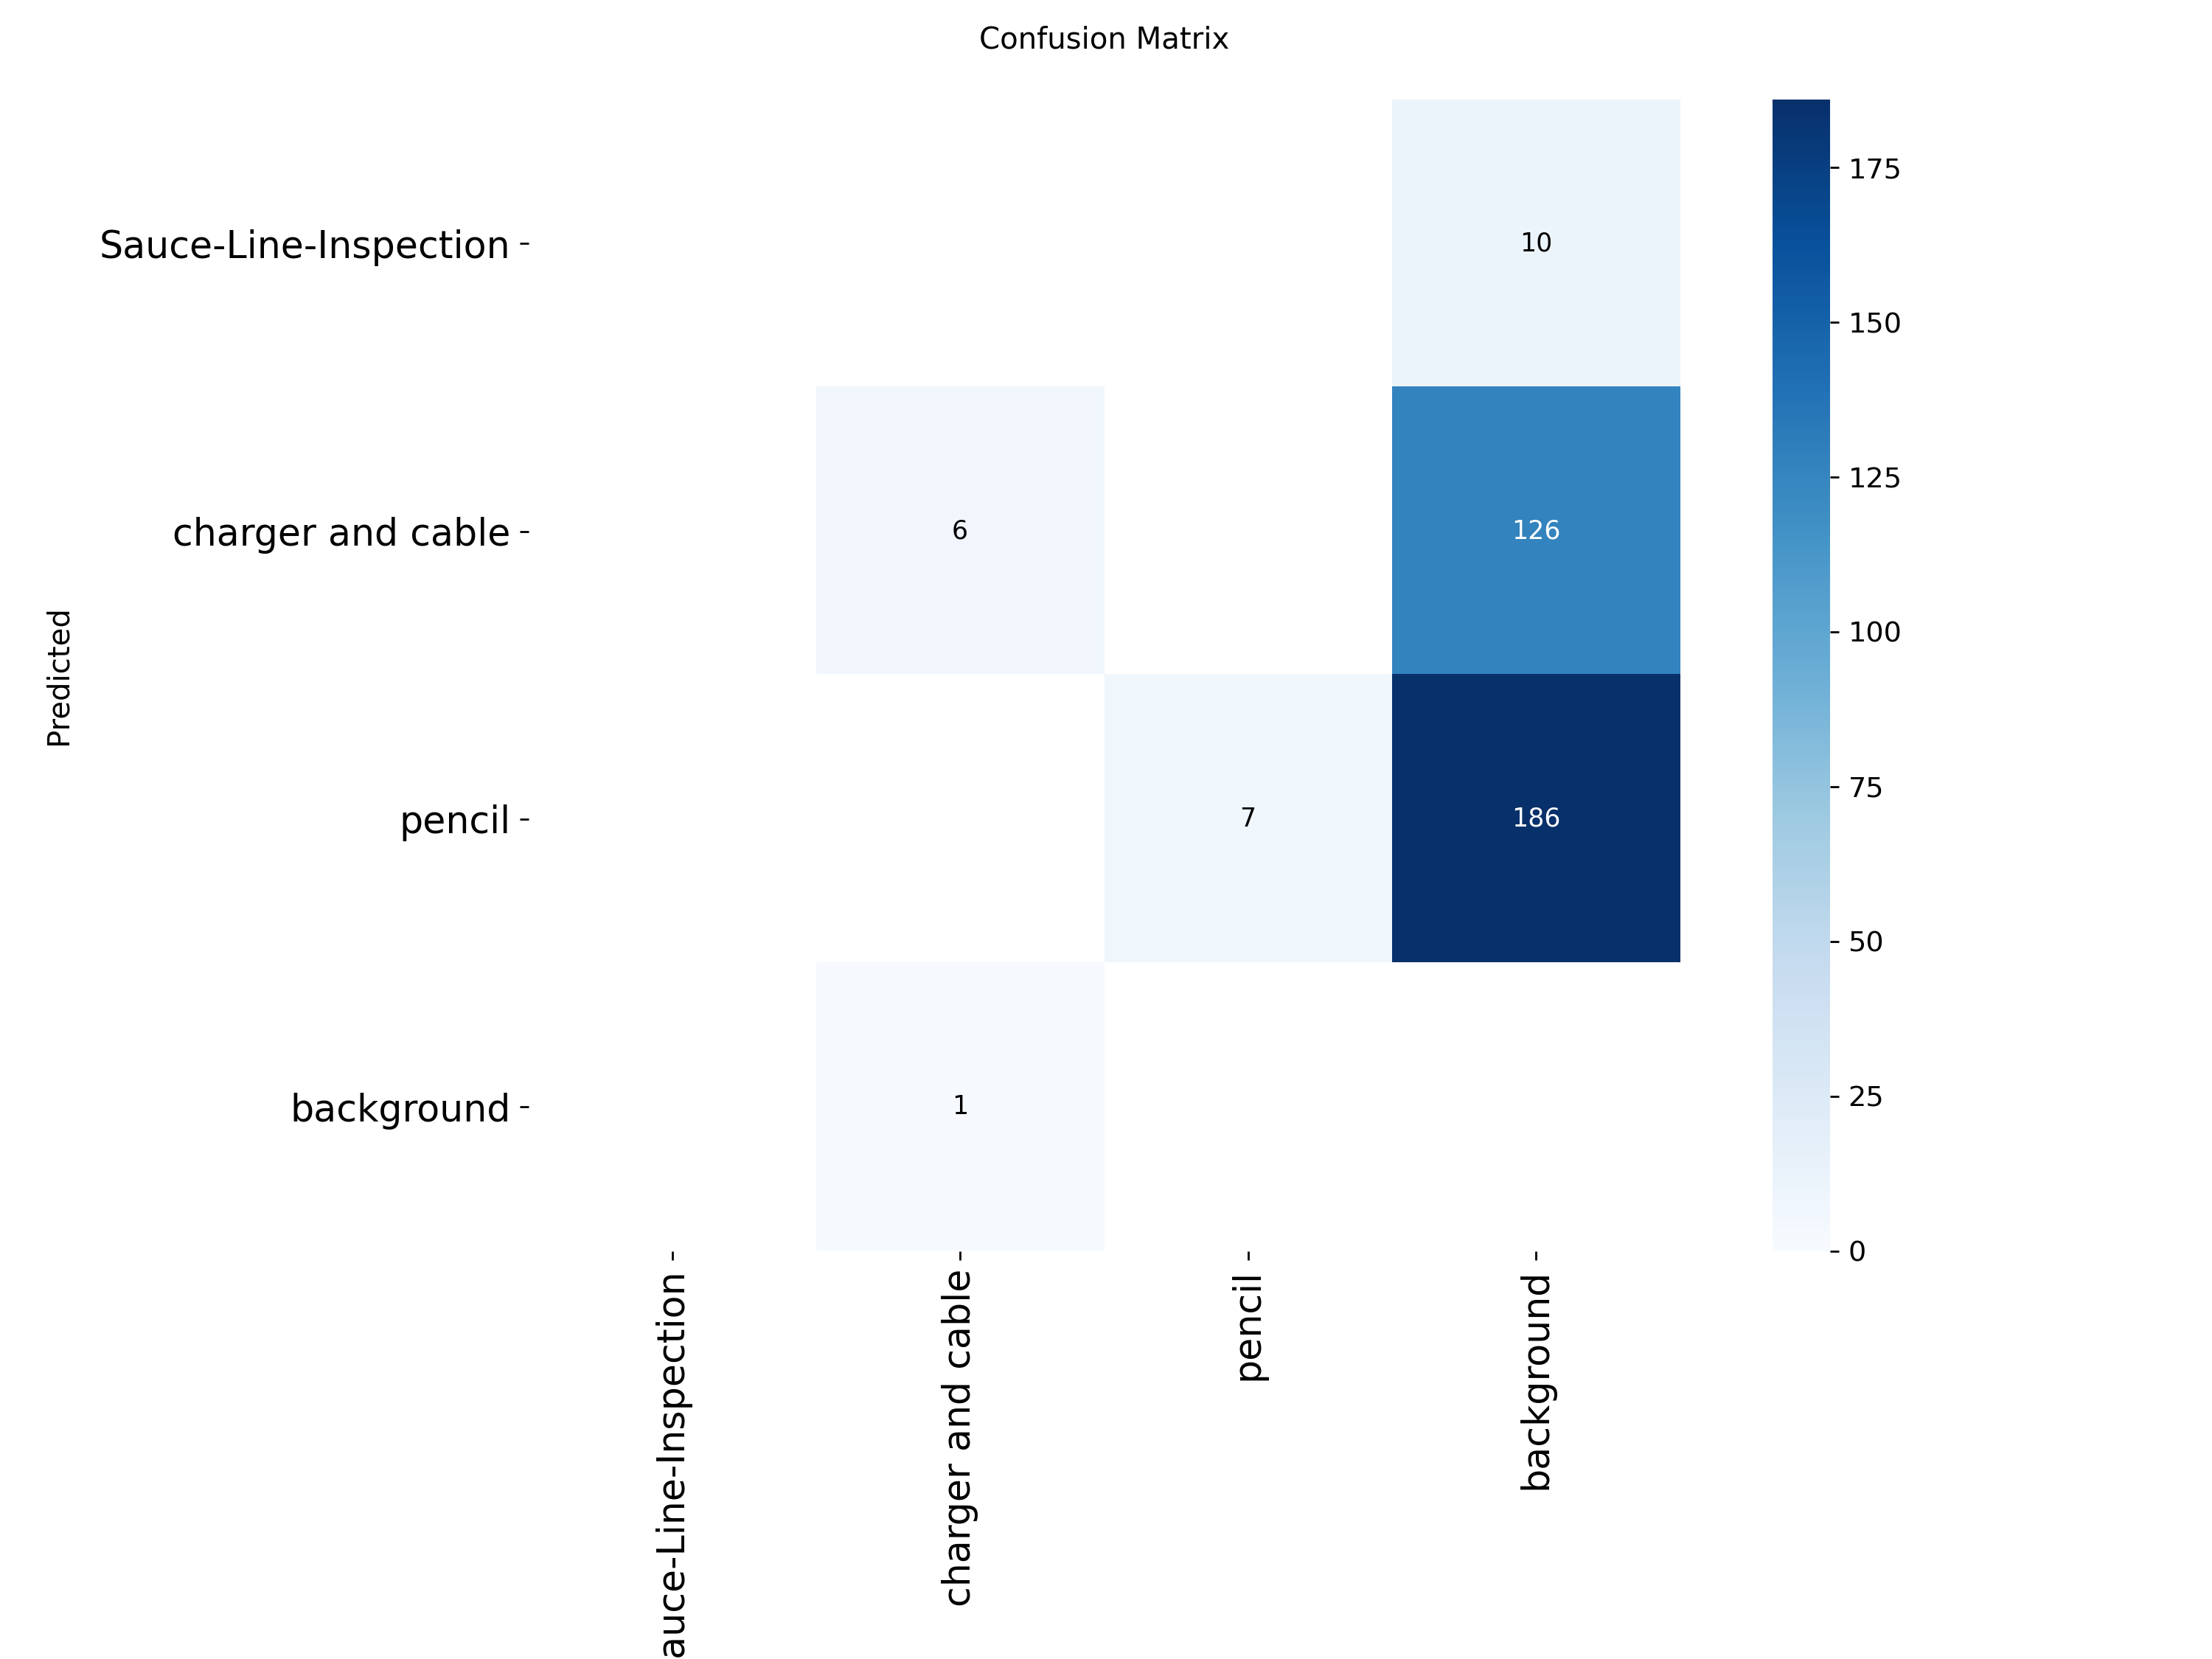

In [35]:
# Evaluate model performance with the best weights of YOLO11s
custom_model = YOLO(BEST_WEIGHTS)
metrics = custom_model.val(data=f'{dataset.location}/data.yaml')

print(f"Precision: {metrics.box.mp:.3f}")
print(f"Recall:    {metrics.box.mr:.3f}")
print(f"mAP50:     {metrics.box.map50:.3f}")
print(f"mAP50-95:  {metrics.box.map:.3f}")

# Per-class mAP50-95
for i, c in enumerate(metrics.box.ap_class_index):
    print(f"{custom_model.names[int(c)]}: mAP50-95 = {metrics.box.maps[c]:.3f}")

# Training curves and confusion matrix
training_run_dir = os.path.dirname(os.path.dirname(BEST_WEIGHTS))
display(Image(filename=os.path.join(training_run_dir, 'results.png'), width=900))
display(Image(filename=os.path.join(str(metrics.save_dir), 'confusion_matrix.png'), width=600))

#### **Analysis of Results** *(update with your numbers)*

- **mAP50:** `__` — **mAP50-95:** `__` — **Precision:** `__` — **Recall:** `__`
- `cell phone charger` is easier to detect because it has a compact, well-defined shape.
- `pencil` is harder: it is thin and elongated, so small box errors lower the IoU, and it can be confused with pens or markers.
- Improvements: more images per class, more varied backgrounds, and more epochs or a bigger model (`yolo11s`).

### **Step 8: Test Your Custom Model on an Image**

Saving p2.jpg to p2 (2).jpg

image 1/1 /content/p2 (2).jpg: 640x512 1 charger and cable, 1 pencil, 12.3ms
Speed: 2.1ms preprocess, 12.3ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 512)


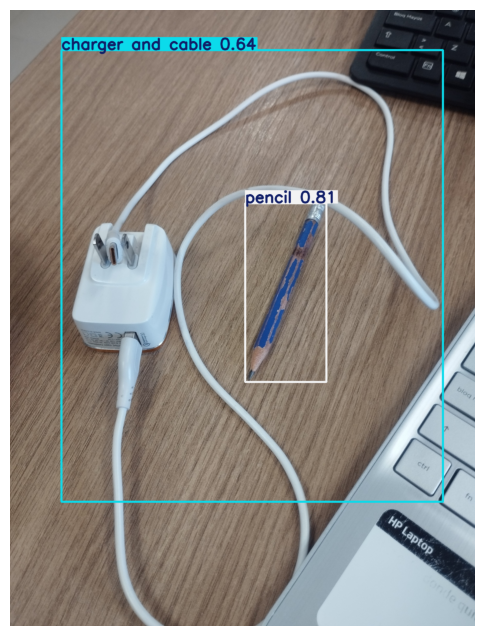

In [34]:
# Upload a test image (charger and/or pencil)
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

# Test on the image
results = custom_model(img_path, conf=0.25)

# Display results
for result in results:
    img = result.plot()  # Plot detections
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(12, 8))
    plt.imshow(img_rgb)
    plt.axis('off')
    plt.show()

### **Step 9: Real-Time Detection with the Webcam**

Colab runs on a remote server, so the webcam is accessed through the browser with JavaScript. Allow camera access when asked and press **Stop camera** to finish.

<IPython.core.display.Javascript object>

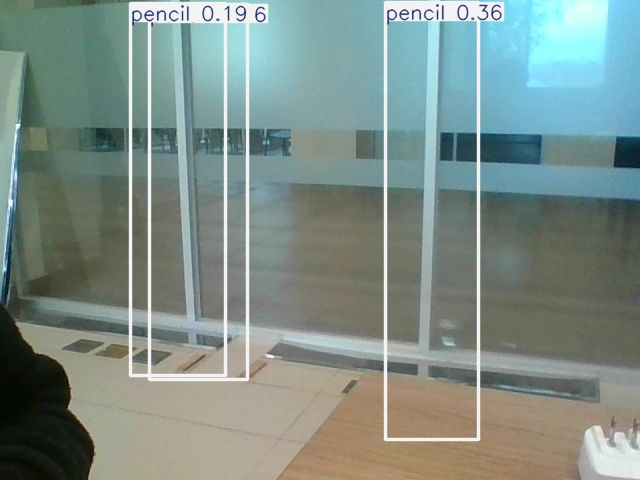

KeyboardInterrupt: 

In [36]:
import numpy as np
from base64 import b64decode
from IPython.display import Javascript
from google.colab.output import eval_js

# JavaScript: open the webcam in the browser and return frames to Python
display(Javascript('''
var video, stream, stopped = false;

async function startCam() {
  const btn = document.createElement('button');
  btn.textContent = 'Stop camera';
  btn.onclick = () => { stopped = true; };
  document.body.appendChild(btn);

  video = document.createElement('video');
  video.style.display = 'none';
  stream = await navigator.mediaDevices.getUserMedia({video: true});
  video.srcObject = stream;
  await video.play();
}

function grabFrame() {
  if (stopped) {
    stream.getTracks().forEach(t => t.stop());
    return '';
  }
  const canvas = document.createElement('canvas');
  canvas.width = 640;
  canvas.height = 480;
  canvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
  return canvas.toDataURL('image/jpeg', 0.8);
}
'''))

eval_js('startCam()')
frame_display = display(None, display_id=True)

# Real-time loop: capture frame -> detect with the custom model -> show result
while True:
    data = eval_js('grabFrame()')
    if not data:
        break
    frame = cv2.imdecode(np.frombuffer(b64decode(data.split(',')[1]), np.uint8), cv2.IMREAD_COLOR)

    results = custom_model(frame, conf=0.15, verbose=False)
    annotated = results[0].plot()  # Draw boxes and labels

    _, jpg = cv2.imencode('.jpg', annotated)
    frame_display.update(Image(data=jpg.tobytes()))

print("Camera stopped.")

## **Activity: Create Your Custom Detector**

1. **Create a RoboFlow account** and set up a new project
2. **Upload at least 20 images** of your custom objects
3. **Annotate all images** with bounding boxes and class labels
4. **Train a YOLO model** on your custom dataset
5. **Test your model** on new images and evaluate its performance
6. **Implement real-time detection** with your custom classes

## **Grading Rubric:**

| **Criteria** | **Points** | **Description** |
|-------------|-----------|----------------|
| **1. Dataset Creation** | 3 | Successfully creates and annotates a custom dataset with at least 50 images and multiple classes in RoboFlow. |
| **2. Model Training** | 3 | Properly trains a YOLOv8 model on the custom dataset with appropriate hyperparameters. |
| **3. Model Evaluation** | 2 | Evaluates model performance with appropriate metrics and provides analysis of results. |
| **4. Custom Detection** | 2 | Implements real-time detection with custom classes and displays results correctly. |
| **5. Documentation** | 1 | Provides clear documentation of the process, including dataset details and model performance. |

**Total: 10 points**

## **Tips for Success:**

- **Quality over quantity**: Well-annotated images are more important than many poorly annotated ones
- **Class balance**: Try to have a similar number of examples for each class
- **Variety**: Include different angles, lighting conditions, and backgrounds
- **Augmentation**: Use RoboFlow's augmentation features to expand your dataset

<p style="text-align: right; font-size:14px; color:gray;">
<b>Prepared by:</b><br>
Manuel Eugenio Morocho-Cayamcela
</p>